## Data dictionary: `npl_matches.csv`

One row per match, 64 rows (32 per season). Types are what `pd.read_csv` gives.

| column | dtype | definition |
|---|---|---|
| `match_id` | int64 | Cricsheet match ID. Unique per row; joins to `npl_deliveries.csv`. |
| `season` | int64 | Season number: 1 = 2024/25, 2 = 2025/26. |
| `date` | str | Match date, `YYYY-MM-DD`. |
| `match_number` | int64 | Match number within the season. League matches are 1–28; playoffs continue as 29–32 in date order. |
| `stage` | str | `League`, `Qualifier 1`, `Eliminator`, `Qualifier 2` or `Final`. |
| `team1` | str | Code of the team that batted first. |
| `team2` | str | Code of the team that batted second. |
| `toss_winner` | str | Code of the team that won the toss. |
| `toss_decision` | str | What the toss winner chose: `bat` or `field`. |
| `winner` | str | Code of the winning team. For the tied match, the team that won the super over (see `is_super_over` in `npl_deliveries.csv`). |
| `win_by_runs` | int64 | Winning margin in runs when `team1` won; 0 otherwise. |
| `win_by_wickets` | int64 | Winning margin in wickets when `team2` won; 0 otherwise. |
| `result` | str | `tie` for the one tied match, which was decided by a super over; NaN for every other match. |
| `total_1stinning` | int64 | Runs scored by `team1`, extras included. Super-over runs are not counted. |
| `total_2ndinning` | int64 | Runs scored by `team2`, extras included. Super-over runs are not counted. |
| `wicket_1stinning` | int64 | Wickets lost by `team1`, 0–10; 10 means bowled out. Retired out counts; retired hurt does not. |
| `wicket_2ndinning` | int64 | Wickets lost by `team2`, same rules. |
| `ball_1stinning` | int64 | Legal balls faced by `team1`; wides, no-balls and super-over balls are not counted. `118` is `19.4` on a scorecard; divide by 6 for overs, e.g. in run rate. |
| `ball_2ndinning` | int64 | Legal balls faced by `team2`, same rules. |
| `player_of_match` | str | Player of the match. |
| `umpire1` | str | First on-field umpire. |
| `umpire2` | str | Second on-field umpire. |

Team codes: `BIK` Biratnagar Kings, `CHR` Chitwan Rhinos, `JAB` Janakpur Bolts, `KAG` Kathmandu Gorkhas, `KAY` Karnali Yaks, `LUL` Lumbini Lions, `POA` Pokhara Avengers, `SUP` Sudur Paschim Royals.

In [304]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)


In [305]:
df = pd.read_csv("../data-csv/npl_matches.csv")


In [306]:
df.shape

(64, 21)

In [307]:
df.head()

,match_id,season,date,match_number,stage,team1,team2,toss_winner,toss_decision,winner,win_by_runs,win_by_wickets,total_1stinning,total_2ndinning,wicket_1stinning,wicket_2ndinning,ball_1stinning,ball_2ndinning,player_of_match,umpire1,umpire2
0,1462596,1,2024-11-30,1,League,BIK,JAB,JAB,field,JAB,0,8,127,131,10,2,114,93,BKEL Milantha,DN Subedi,VK Jha
1,1462640,1,2024-12-02,2,League,KAG,CHR,CHR,field,CHR,0,5,111,114,9,5,120,103,Sohail Tanvir,BB Pradhan,HR Giri
2,1462641,1,2024-12-02,3,League,KAY,JAB,KAY,bat,JAB,0,8,141,142,7,2,120,91,AK Sah,Bismillah Shinwari,Rashid Riaz
3,1462642,1,2024-12-03,4,League,SUP,BIK,BIK,field,SUP,90,0,182,92,7,10,120,97,DS Airee,DN Subedi,HR Giri
4,1462643,1,2024-12-03,5,League,CHR,POA,POA,field,CHR,87,0,161,74,7,10,120,80,R Dhakal,Bismillah Shinwari,VK Jha


In [308]:
df.tail()

,match_id,season,date,match_number,stage,team1,team2,toss_winner,toss_decision,winner,win_by_runs,win_by_wickets,total_1stinning,total_2ndinning,wicket_1stinning,wicket_2ndinning,ball_1stinning,ball_2ndinning,player_of_match,umpire1,umpire2
59,1511004,2,2025-12-07,28,League,KAY,JAB,JAB,field,KAY,3,0,129,126,9,7,120,120,WG Bosisto,DN Subedi,VK Jha
60,1511005,2,2025-12-09,29,Qualifier 1,SUP,BIK,BIK,field,SUP,77,0,155,78,7,10,120,85,B Bhandari,LE Hannibal,RR Wimalasiri
61,1511006,2,2025-12-10,30,Eliminator,KAG,LUL,KAG,bat,LUL,0,4,111,112,10,6,115,106,S Malla,BB Pradhan,LE Hannibal
62,1511007,2,2025-12-11,31,Qualifier 2,LUL,BIK,BIK,field,LUL,40,0,134,94,8,10,120,107,TR Bhandari,LE Hannibal,RR Wimalasiri
63,1511008,2,2025-12-13,32,Final,SUP,LUL,SUP,bat,LUL,0,6,85,86,10,4,115,54,R Trumpelmann,LE Hannibal,RR Wimalasiri


In [309]:
df.sample(10)

,match_id,season,date,match_number,stage,team1,team2,toss_winner,toss_decision,winner,win_by_runs,win_by_wickets,total_1stinning,total_2ndinning,wicket_1stinning,wicket_2ndinning,ball_1stinning,ball_2ndinning,player_of_match,umpire1,umpire2
14,1462653,1,2024-12-08,15,League,CHR,SUP,CHR,bat,CHR,33,0,164,131,5,10,120,110,Hassan Eisakhil,Bismillah Shinwari,Rashid Riaz
46,1510991,2,2025-11-28,15,League,KAG,CHR,CHR,field,KAG,53,0,142,89,10,10,118,104,JA Simpson,BB Pradhan,RR Wimalasiri
16,1462655,1,2024-12-10,17,League,POA,KAY,POA,bat,KAY,0,7,103,106,10,3,99,90,WG Bosisto,Bismillah Shinwari,Sanjay Gurung
15,1462654,1,2024-12-10,16,League,LUL,CHR,CHR,field,LUL,33,0,167,134,6,8,120,120,RK Paudel,BB Pradhan,HR Giri
0,1462596,1,2024-11-30,1,League,BIK,JAB,JAB,field,JAB,0,8,127,131,10,2,114,93,BKEL Milantha,DN Subedi,VK Jha
8,1462647,1,2024-12-05,9,League,SUP,KAG,KAG,field,SUP,73,0,167,94,6,10,120,95,N Saud,HR Giri,Rashid Riaz
27,1462666,1,2024-12-16,28,League,KAY,SUP,SUP,field,SUP,0,6,101,105,10,4,120,92,DS Airee,HR Giri,Sanjay Gurung
18,1462657,1,2024-12-11,19,League,KAG,LUL,KAG,bat,KAG,18,0,103,85,10,10,116,116,Karan KC,HR Giri,Rashid Riaz
36,1510981,2,2025-11-20,5,League,CHR,LUL,LUL,field,LUL,0,6,142,146,7,4,120,111,R Trumpelmann,DN Subedi,RR Wimalasiri
34,1510979,2,2025-11-18,3,League,BIK,POA,POA,field,BIK,53,0,220,167,6,10,120,113,Lokesh Bam,BB Pradhan,RR Wimalasiri


In [310]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   match_id          64 non-null     int64
 1   season            64 non-null     int64
 2   date              64 non-null     str  
 3   match_number      64 non-null     int64
 4   stage             64 non-null     str  
 5   team1             64 non-null     str  
 6   team2             64 non-null     str  
 7   toss_winner       64 non-null     str  
 8   toss_decision     64 non-null     str  
 9   winner            64 non-null     str  
 10  win_by_runs       64 non-null     int64
 11  win_by_wickets    64 non-null     int64
 12  total_1stinning   64 non-null     int64
 13  total_2ndinning   64 non-null     int64
 14  wicket_1stinning  64 non-null     int64
 15  wicket_2ndinning  64 non-null     int64
 16  ball_1stinning    64 non-null     int64
 17  ball_2ndinning    64 non-null     int64
 18  pla

In [311]:
df.describe()

,match_id,season,match_number,win_by_runs,win_by_wickets,total_1stinning,total_2ndinning,wicket_1stinning,wicket_2ndinning,ball_1stinning,ball_2ndinning
count,64.00,64.00,64.00,64.00,64.00,64.00,64.00,64.00,64.00,64.00,64.00
mean,1486822.83,1.50,16.50,17.05,2.83,147.53,131.95,7.22,6.77,119.23,106.58
std,24360.74,0.50,9.31,25.15,3.13,26.82,28.65,2.06,2.90,2.88,14.53
min,1462596.00,1.00,1.00,0.00,0.00,85.00,51.00,2.00,0.00,99.00,54.00
25%,1462654.75,1.00,8.75,0.00,0.00,131.50,118.75,6.00,4.00,120.00,101.00
50%,1486823.50,1.50,16.50,0.00,1.50,144.50,134.50,7.00,7.00,120.00,110.00
75%,1510992.25,2.00,24.25,32.25,6.00,166.25,148.50,9.00,10.00,120.00,118.25
max,1511008.00,2.00,32.00,90.00,10.00,220.00,193.00,10.00,10.00,120.00,120.00


In [312]:
df.duplicated().sum()                          # count duplicate rows

np.int64(0)

Relevant DATA TYPE CONVERSION and missing values handaling

In [313]:
int8_dtype_cols=["match_number","win_by_runs","win_by_wickets","total_1stinning",
                "total_2ndinning","wicket_1stinning","wicket_2ndinning","ball_1stinning","ball_2ndinning"]

df[int8_dtype_cols]=df[int8_dtype_cols].astype("uint8")

df['date'] = pd.to_datetime(df['date'], format='%Y-%m-%d')

<center><h3>UNIVARIATE ANALYSIS</h3></center>


### `total_1stinning`

#### Conclusion
The first-inning scores are nearly perfectly **normally distributed**. The scores center around an average of **147**. Thanks to this normal distribution shape, we can see that most matches safely land between **120 and 174**. The lowest score was **85**, and there was just one unusually high outlier match at **220**.


In [314]:
df["total_1stinning"].describe()

count    64.00
mean    147.53
std      26.82
min      85.00
25%     131.50
50%     144.50
75%     166.25
max     220.00
Name: total_1stinning, dtype: float64

<Axes: xlabel='total_1stinning', ylabel='Count'>

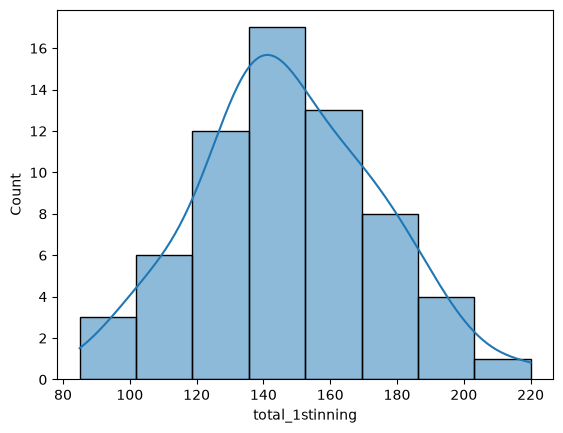

In [315]:
sns.histplot(df["total_1stinning"], kde=True)


Axes(0.125,0.11;0.775x0.77)


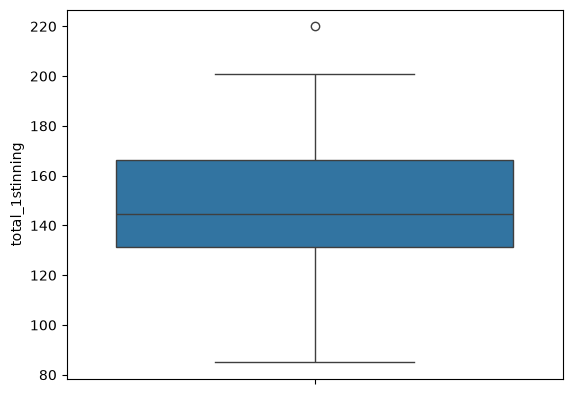

In [316]:
print(sns.boxplot(df["total_1stinning"]))

In [317]:
print(df["total_1stinning"].skew())
df["total_1stinning"].kurt()

0.16189738232093975


np.float64(0.020023731658313615)

### total_2ndinning

#### Conclusion
The second-inning scores show a **mildly negative skew** (skewness = -0.377)  because of **two distinct low outliers** visible at the bottom of the distribution. Despite these extreme low values, the overall shape still closely resembles a standard normal bell curve, centered around the 130–140 score mark.


In [318]:
df["total_2ndinning"].describe()

count    64.00
mean    131.95
std      28.65
min      51.00
25%     118.75
50%     134.50
75%     148.50
max     193.00
Name: total_2ndinning, dtype: float64

<Axes: xlabel='total_2ndinning', ylabel='Count'>

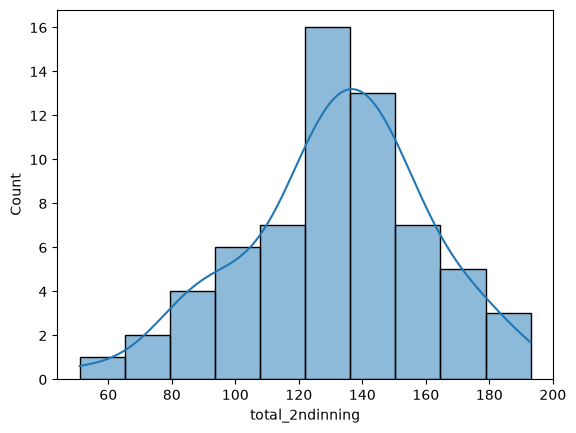

In [319]:
sns.histplot(df["total_2ndinning"],kde=True)


<Axes: ylabel='total_2ndinning'>

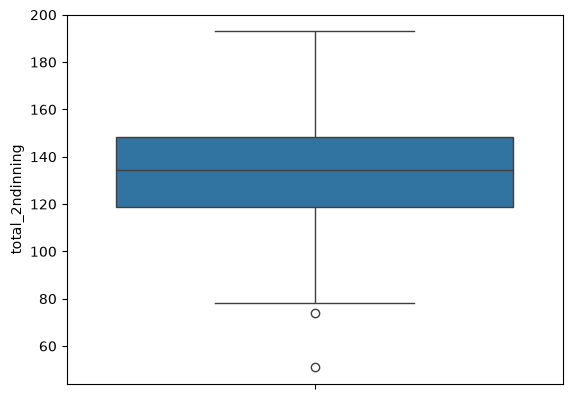

In [320]:
sns.boxplot(df["total_2ndinning"])

In [321]:
print(df["total_2ndinning"].skew())
df["total_2ndinning"].kurt()

-0.3779458187864062


np.float64(0.195080120956042)

### wicket_1st_inning

### conclusion
`wicket_1stinning` is a **discrete count**. The observed values run from **2 to 10** (the possible range is 0 to 10), with a mean of **7.22** and a median of **7**. The distribution is **not normal**: it has two peaks, one at **7 wickets** (13 matches) and one at **10 wickets** (12 matches, **18.75%**), where the team was all out. The second peak exists because an innings stops at 10 wickets, so values pile up at that limit. The skewness of **-0.34** looks close to symmetric only because this pile-up on the right offsets the tail of low values (2–5) on the left. The box plot shows no outliers.


In [322]:
df["wicket_1stinning"].describe()

count   64.00
mean     7.22
std      2.06
min      2.00
25%      6.00
50%      7.00
75%      9.00
max     10.00
Name: wicket_1stinning, dtype: float64

<Axes: xlabel='wicket_1stinning', ylabel='Count'>

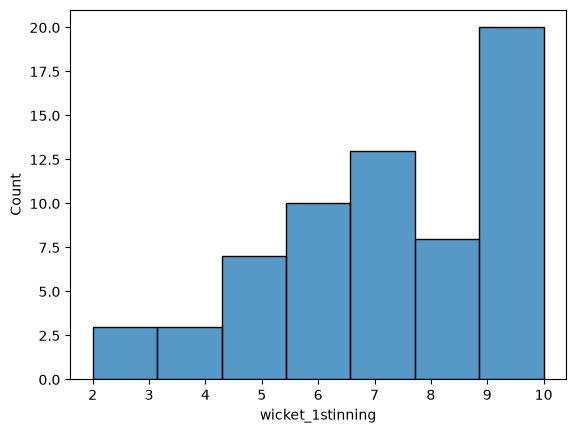

In [323]:
sns.histplot(df["wicket_1stinning"])


<Axes: ylabel='wicket_1stinning'>

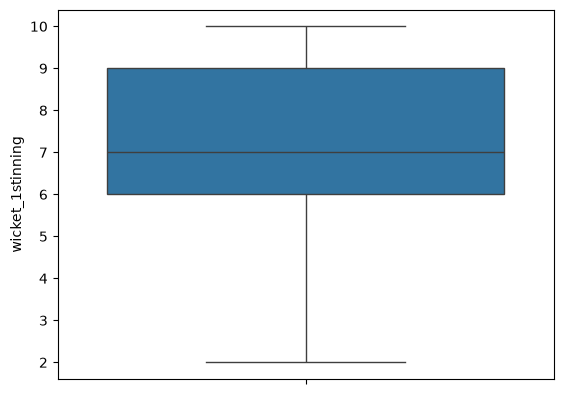

In [324]:
sns.boxplot(df["wicket_1stinning"])

<Axes: xlabel='wicket_1stinning', ylabel='count'>

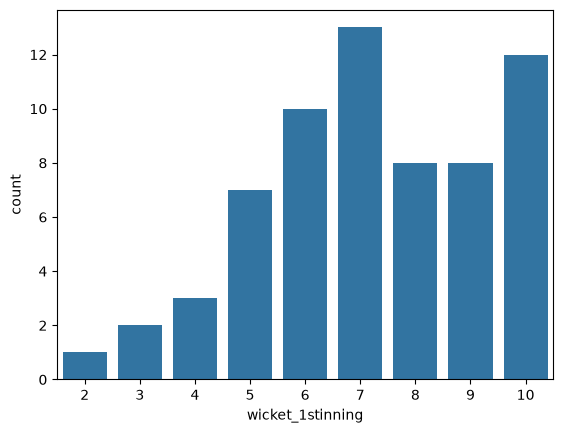

In [325]:
sns.countplot(data=df, x="wicket_1stinning")

In [326]:
print(df["wicket_1stinning"].skew())
df["wicket_1stinning"].kurt()

-0.3378694762473949


np.float64(-0.5317237696051227)

In [327]:
(df["wicket_1stinning"] == 10).mean() * 100

np.float64(18.75)

### `ball_1st inning`

#### Conclusion
`ball_1stinning` is a **nearly constant** column. **55 of 64** innings (**86%**) lasted the full **120 balls**, and no other value appears more than twice. The remaining **9** innings ended early, between **99 and 119** balls, and every one of them was **all out**. So the column carries one yes/no fact: whether the innings ended early. Those 9 short innings averaged about **115** runs, against **153** for the full ones.


In [328]:
df["ball_1stinning"].describe()

count    64.00
mean    119.23
std       2.88
min      99.00
25%     120.00
50%     120.00
75%     120.00
max     120.00
Name: ball_1stinning, dtype: float64

In [329]:
df["ball_1stinning"].value_counts(normalize=True)*100

ball_1stinning
120   85.94
118    3.12
115    3.12
114    1.56
99     1.56
116    1.56
117    1.56
119    1.56
Name: proportion, dtype: float64

In [330]:
df[df["ball_1stinning"]<120]["total_1stinning"].mean()

np.float64(114.66666666666667)

In [331]:
df[df["ball_1stinning"]==120]["total_1stinning"].mean()

np.float64(152.9090909090909)

### `wicket_2ndinning` 


#### Conclusion
`wicket_2ndinning` is a **discrete count** from **0 to 10**, with a mean of **6.77** and a median of **7**. there is a spike at **10 wickets** (19 matches, **29.7%** all out) and a lower hump around **4 to 5**. The mean and median fall between the two peaks, where few matches sit. 

In [332]:
df["wicket_2ndinning"].describe()

count   64.00
mean     6.77
std      2.90
min      0.00
25%      4.00
50%      7.00
75%     10.00
max     10.00
Name: wicket_2ndinning, dtype: float64

In [333]:
df["wicket_2ndinning"].value_counts(normalize=True)*100

wicket_2ndinning
10   29.69
4    12.50
5    10.94
8     9.38
7     7.81
9     7.81
6     7.81
2     6.25
3     4.69
0     1.56
1     1.56
Name: proportion, dtype: float64

<Axes: xlabel='wicket_2ndinning', ylabel='Count'>

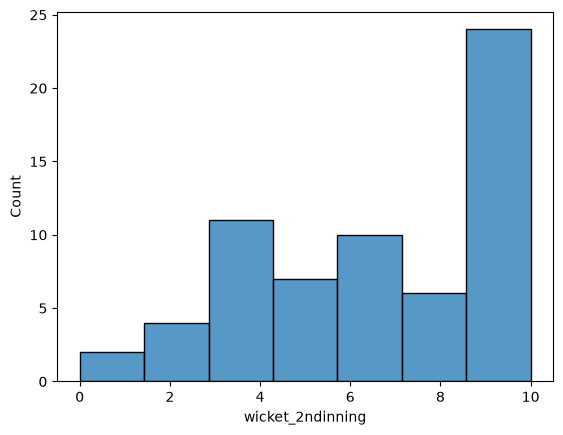

In [334]:
sns.histplot(df["wicket_2ndinning"])

### `ball_2nd_inning`


#### Conclusion
`ball_2ndinning` is a **numeric** column with **30** different values, from **54 to 120** balls (mean **106.6**, median **110**). Unlike the first innings, only **13 of 64** innings (**20%**) lasted the full 120 balls. The distribution is **strongly left-skewed** (skew **-1.45**) and **not normal**: there is a hard cap at 120 and a long tail of short innings, with four low outliers (**54, 71, 73, 74**).


In [335]:
df["ball_2ndinning"].describe()

count    64.00
mean    106.58
std      14.53
min      54.00
25%     101.00
50%     110.00
75%     118.25
max     120.00
Name: ball_2ndinning, dtype: float64

<Axes: xlabel='ball_2ndinning', ylabel='Count'>

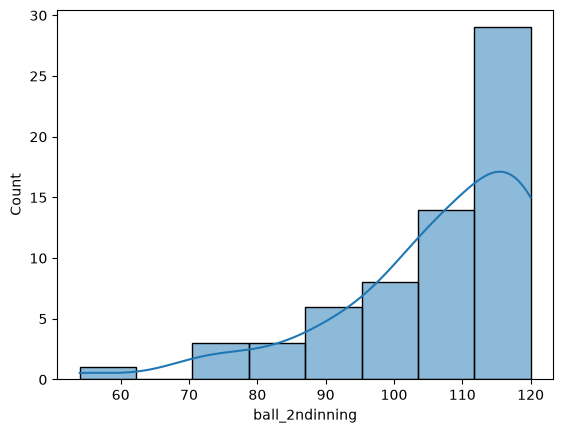

In [336]:
sns.histplot(df["ball_2ndinning"],kde=True)


In [337]:
print(f"unique_count={df["ball_2ndinning"].nunique()}")
df["ball_2ndinning"].value_counts().sort_index(ascending=False).reset_index()


unique_count=30


,ball_2ndinning,count
0,120,13
1,119,3
2,118,3
3,117,1
4,116,3
5,115,3
6,114,2
7,113,1
8,111,2
9,110,2


In [338]:
df["ball_2ndinning"].skew()

np.float64(-1.4530846772276855)

<Axes: ylabel='ball_2ndinning'>

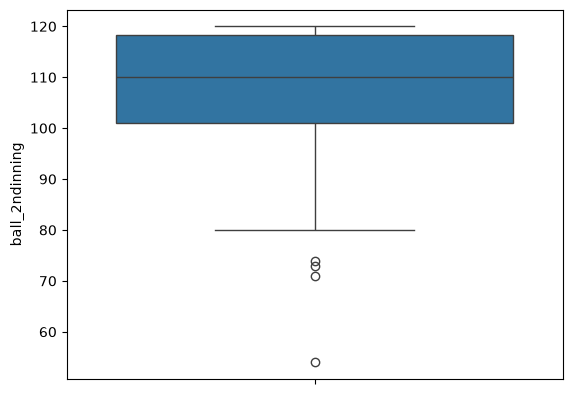

In [339]:
sns.boxplot(df["ball_2ndinning"])

